# Week 2. Langevin dynamics

This notebook accompanies Chapter 3 of the notes. Each section illustrates one of the convergence results
for the Langevin diffusion
$$
  \mathrm dX_t=-\nabla U(X_t)\,\mathrm dt+\sqrt2\,\mathrm dB_t,\qquad\mu\propto e^{-U},
$$
and for its discretisation, the unadjusted Langevin algorithm (ULA).

1. Contraction in Wasserstein distance under strong convexity, by synchronous coupling.
2. Convergence in $\chi^2$, relative entropy and total variation, and why the $\chi^2$ route is pessimistic in
   high dimension.
3. Metastability. When $\mu$ has two well-separated modes, the time to cross between them, and the Poincaré
   constant, grow exponentially with the separation.
4. The bias of ULA.

Everything runs on a laptop CPU in about a minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad

rng = np.random.default_rng(1)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Synchronous coupling

Take the strongly convex potential
$$
  U(x)=\frac\alpha2|x|^2+\sum_{i=1}^n\log\cosh(x_i),\qquad\alpha\,I_n\preceq\nabla^2U(x)\preceq(\alpha+1)\,I_n ,
$$
which is not Gaussian. Run two copies of the Langevin diffusion from different points, driven by the *same*
Brownian motion. The noise cancels in their difference, and strong convexity gives the pathwise bound
$|X_t-Y_t|\le e^{-\alpha t}|X_0-Y_0|$. Taking the initial points distributed according to an optimal coupling
gives $W_2(\mu_t,\mu)\le e^{-\alpha t}W_2(\mu_0,\mu)$.

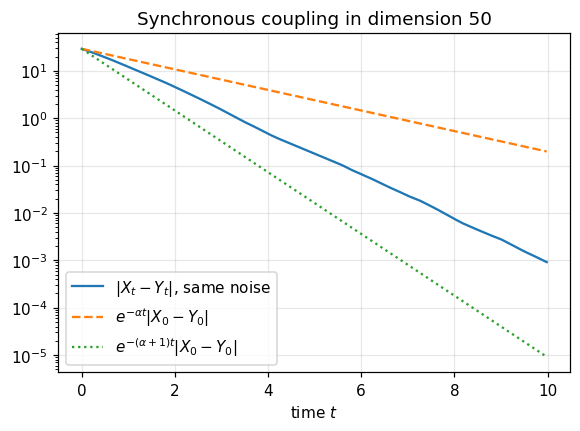

In [2]:
n, alpha, h, T = 50, 0.5, 1e-3, 10.0
grad_U = lambda x: alpha * x + np.tanh(x)

x = 4.0 * np.ones(n)                 # two very different starting points
y = rng.standard_normal(n)
ts, dist = [0.0], [np.linalg.norm(x - y)]
for k in range(int(T / h)):
    xi = rng.standard_normal(n)       # the same noise for both copies
    x = x - h * grad_U(x) + np.sqrt(2 * h) * xi
    y = y - h * grad_U(y) + np.sqrt(2 * h) * xi
    if k % 20 == 0:
        ts.append((k + 1) * h); dist.append(np.linalg.norm(x - y))
ts, dist = np.array(ts), np.array(dist)

plt.figure(figsize=(6, 4))
plt.semilogy(ts, dist, label=r"$|X_t-Y_t|$, same noise")
plt.semilogy(ts, dist[0] * np.exp(-alpha * ts), "--", label=r"$e^{-\alpha t}|X_0-Y_0|$")
plt.semilogy(ts, dist[0] * np.exp(-(alpha + 1) * ts), ":", label=r"$e^{-(\alpha+1)t}|X_0-Y_0|$")
plt.xlabel("time $t$"); plt.legend(); plt.title("Synchronous coupling in dimension 50")
plt.show()

The distance decreases deterministically, between the rates given by the smallest and largest eigenvalues
of the Hessian. Near the origin $\nabla^2U\approx(\alpha+1)I_n$ and the contraction is faster, while far away
only $\alpha$ is guaranteed.

## 2. Convergence in $\chi^2$, relative entropy and total variation

For the Gaussian target $\mu=\gamma_n$ the Langevin diffusion is the Ornstein–Uhlenbeck process, and from
$X_0\sim\mathcal N(m,I_n)$ we have $X_t\sim\mathcal N(e^{-t}m,I_n)$. Everything is then explicit,
$$
  \mathrm{KL}(\mu_t\|\gamma_n)=\tfrac12|m|^2e^{-2t},\qquad
  \chi^2(\mu_t\|\gamma_n)=e^{|m|^2e^{-2t}}-1,\qquad
  \mathrm{TV}(\mu_t,\gamma_n)=2\Phi\bigl(\tfrac12|m|e^{-t}\bigr)-1 .
$$
Since $C_{\mathrm P}=C_{\mathrm{LSI}}=1$, the theorems of Chapter 3 give the bounds $\chi^2(\mu_t\|\gamma_n)\le e^{-2t}\chi^2(\mu_0\|\gamma_n)$
and $\mathrm{KL}(\mu_t\|\gamma_n)\le e^{-2t}\mathrm{KL}(\mu_0\|\gamma_n)$. We take a starting point at the typical distance
$|m|=\sqrt n$, with $n=200$, and turn each bound into a bound on total variation.

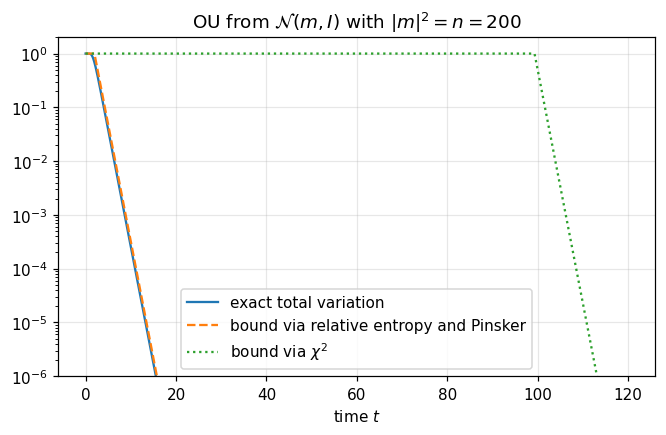

time for TV <= 0.01, exact           : 6.4
time for TV <= 0.01, relative entropy: 6.6
time for TV <= 0.01, chi^2           : 104.0


In [3]:
n = 200; m2 = float(n)
t = np.linspace(0, 120, 2000)
tv_exact = 2 * norm.cdf(0.5 * np.sqrt(m2) * np.exp(-t)) - 1
tv_from_kl = np.minimum(1, np.sqrt(0.5 * 0.5 * m2 * np.exp(-2 * t)))                 # Pinsker
log_chi2_bound = -2 * t + m2                                                         # log of e^{-2t}(e^{|m|^2}-1)
tv_from_chi2 = np.minimum(1, 0.5 * np.exp(0.5 * log_chi2_bound))

plt.figure(figsize=(7, 4))
plt.semilogy(t, tv_exact, label="exact total variation")
plt.semilogy(t, tv_from_kl, "--", label="bound via relative entropy and Pinsker")
plt.semilogy(t, tv_from_chi2, ":", label=r"bound via $\chi^2$")
plt.ylim(1e-6, 2); plt.xlabel("time $t$"); plt.legend()
plt.title(rf"OU from $\mathcal{{N}}(m,I)$ with $|m|^2=n={n}$")
plt.show()
for name, curve in [("exact", tv_exact), ("relative entropy", tv_from_kl), ("chi^2", tv_from_chi2)]:
    print(f"time for TV <= 0.01, {name:16s}: {t[np.argmax(curve <= 0.01)]:.1f}")

The relative entropy bound reaches small total variation after a time of order $\log n$, like the truth. The
$\chi^2$ bound needs a time of order $n$, because $\chi^2(\mu_0\|\gamma_n)=e^{|m|^2}-1$ is exponentially large. For product
measures relative entropy adds up over coordinates while $1+\chi^2$ multiplies, and this is why log-Sobolev
inequalities are the right tool in high dimension.

*Things to try.* Change $n$ to $20$ and $2000$ and compare the three times.

## 3. Metastability and the Poincaré constant

Let $\mu=\frac12\mathcal N(-ae_1,I_n)+\frac12\mathcal N(ae_1,I_n)$. Both components have the same covariance and the same
mean in the directions orthogonal to $e_1$, so the dynamics of the first coordinate decouples from the
others, and we only simulate it. We start in the left mode and record the first time at which the first
coordinate becomes positive.

In [4]:
def score_1d(x, a):
    # first coordinate of the score of (N(-a e1, I) + N(a e1, I))/2
    return -x + a * np.tanh(a * x)

def mean_crossing_time(a, M=400, h=5e-3, t_max=4000.0):
    x = -a * np.ones(M); t_cross = np.full(M, np.nan); t = 0.0
    alive = np.ones(M, dtype=bool)
    while alive.any() and t < t_max:
        x[alive] += h * score_1d(x[alive], a) + np.sqrt(2 * h) * rng.standard_normal(alive.sum())
        t += h
        crossed = alive & (x > 0)
        t_cross[crossed] = t; alive &= ~crossed
    return np.nanmean(t_cross), alive.mean()

seps = [1.0, 1.5, 2.0, 2.5, 3.0, 3.25]
times = []
for a in seps:
    tm, frac_alive = mean_crossing_time(a)
    times.append(tm)
    print(f"a = {a:4.2f}   mean crossing time {tm:8.1f}   (fraction not yet crossed {frac_alive:.2f})")

a = 1.00   mean crossing time      1.6   (fraction not yet crossed 0.00)
a = 1.50   mean crossing time      3.9   (fraction not yet crossed 0.00)
a = 2.00   mean crossing time      8.6   (fraction not yet crossed 0.00)


a = 2.50   mean crossing time     22.6   (fraction not yet crossed 0.00)


a = 3.00   mean crossing time     73.6   (fraction not yet crossed 0.00)


a = 3.25   mean crossing time    157.9   (fraction not yet crossed 0.00)


We compare with a lower bound on the Poincaré constant. For a test function $\varphi$ with $\varphi(x)=\pm1$ deep in the
two modes, $C_{\mathrm P}\ge\mathrm{Var}_\mu(\varphi)/\int|\nabla\varphi|^2\,\mathrm d\mu$. We take $\varphi(x)=\tanh(ax_1)$, which only depends on the first
coordinate, and compute both integrals numerically.

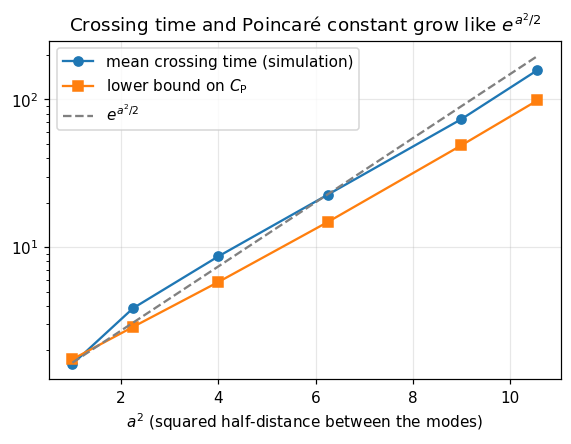

In [5]:
def poincare_lower_bound(a):
    dens = lambda x: 0.5 * (norm.pdf(x, -a, 1) + norm.pdf(x, a, 1))
    var = quad(lambda x: np.tanh(a * x)**2 * dens(x), -np.inf, np.inf)[0]        # the mean is 0 by symmetry
    energy = quad(lambda x: (a * (1 - np.tanh(a * x)**2))**2 * dens(x), -np.inf, np.inf)[0]
    return var / energy

cp = [poincare_lower_bound(a) for a in seps]
a2 = np.array(seps)**2
plt.figure(figsize=(6, 4))
plt.semilogy(a2, times, "o-", label="mean crossing time (simulation)")
plt.semilogy(a2, cp, "s-", label=r"lower bound on $C_{\mathrm{P}}$")
plt.semilogy(a2, np.exp(a2 / 2), "--", c="gray", label=r"$e^{a^2/2}$")
plt.xlabel("$a^2$ (squared half-distance between the modes)"); plt.legend()
plt.title("Crossing time and Poincaré constant grow like $e^{a^2/2}$")
plt.show()

Both quantities grow like $e^{a^2/2}$. The density at the midpoint, relative to the modes, is about $e^{-a^2/2}$, so the
diffusion has to climb a barrier of height $a^2/2$ in $-\log\mu$. This is the Arrhenius law of Chapter 4, and it
explains why Langevin dynamics cannot learn the weights of well-separated modes, as we saw in Week 1.

## 4. The bias of ULA

ULA replaces the diffusion by $X_{k+1}=X_k-h\nabla U(X_k)+\sqrt{2h}\,\xi_k$. Its stationary law $\mu_h$ is not $\mu$. For a
Gaussian target $\mathcal N(0,\alpha^{-1}I_n)$ we found in Week 1 that $\mu_h=\mathcal N(0,v_hI_n)$ with $v_h=1/(\alpha(1-\alpha h/2))$, so
$$
  W_2(\mu_h,\mu)=\sqrt n\,\bigl|\sqrt{v_h}-\alpha^{-1/2}\bigr|\approx\frac{\sqrt{n}\,\alpha^{1/2}h}{4} .
$$
For the non-Gaussian potential of Section 1 there is no formula, but we can measure the bias of a statistic,
here $\mathbb E|X|^2/n$, against a run with a very small step.

reference E|X|^2/n (h = 0.01): 0.9077
h = 0.400   bias of E|X|^2/n = +0.2911   bias / h = 0.728
h = 0.200   bias of E|X|^2/n = +0.1250   bias / h = 0.625
h = 0.100   bias of E|X|^2/n = +0.0555   bias / h = 0.555
h = 0.050   bias of E|X|^2/n = +0.0237   bias / h = 0.475


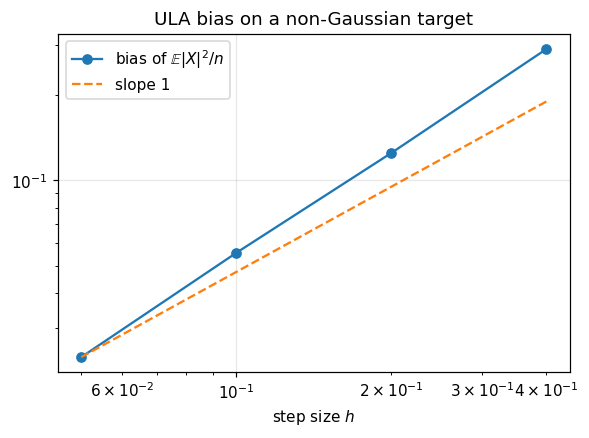

In [6]:
n, alpha = 50, 0.5
grad_U = lambda x: alpha * x + np.tanh(x)

def ula_second_moment(h, M=2000, T=60.0, burn_in=10.0):
    # average E|X|^2/n over particles and over the iterations after the burn-in period
    x = rng.standard_normal((M, n)); acc, cnt = 0.0, 0
    for k in range(int(T / h)):
        x = x - h * grad_U(x) + np.sqrt(2 * h) * rng.standard_normal((M, n))
        if k * h >= burn_in:
            acc += np.mean(x**2); cnt += 1
    return acc / cnt

hs = np.array([0.4, 0.2, 0.1, 0.05])
ref = ula_second_moment(0.01)
bias = np.array([ula_second_moment(h) - ref for h in hs])
print(f"reference E|X|^2/n (h = 0.01): {ref:.4f}")
for h, b in zip(hs, bias):
    print(f"h = {h:5.3f}   bias of E|X|^2/n = {b:+.4f}   bias / h = {b / h:.3f}")

plt.figure(figsize=(6, 4))
plt.loglog(hs, np.abs(bias), "o-", label=r"bias of $\mathbb{E}|X|^2/n$")
plt.loglog(hs, hs * np.abs(bias[-1]) / hs[-1], "--", label="slope 1")
plt.xlabel("step size $h$"); plt.legend(); plt.title("ULA bias on a non-Gaussian target")
plt.show()

The bias of this statistic is of order $h$. The ratio bias$/h$ settles as $h$ decreases, and the drift of the ratio
for the larger steps is a correction of order $h^2$. Chapter 3 proves $W_2(\mu_h,\mu)\lesssim\kappa\sqrt{nh}$, which is enough for a
polynomial complexity bound but not sharp. Under extra smoothness the bias is of order $h$, as observed here.

*Things to try.* Replace $\log\cosh$ by a potential that is not strongly convex, such as
$U(x)=\frac14|x|^4$, and see what happens to ULA with a large step.